# 06 — Baseline Models and the Initial Training of Release 1

## 1. Purpose of This Notebook

This notebook trains the first survival model of Darb, the model that the conversational agent uses in Release 1
(Sprint 2), and the simplest model against which every later model is compared. Two models are trained on the
training businesses of the model table (Notebook 05) and compared on the validation businesses:

1. *Always the average.* Every business receives the failure rate of the training businesses. Any useful model must
   do better than this one.
2. *Logistic regression.* The chance of failing within the first year is modelled from the inputs, each input
   category adding a fixed amount to the log-odds of failing. It is fast, stable and its weights can be read
   directly, which makes it the baseline.

**Inputs of Release 1.** The model uses only the inputs that the conversational agent confirms with the founder in
Release 1: the economic sector (ISIC section) and the region. The other business inputs of Notebook 05 (legal form,
capital, city and e-commerce) require the agent to ask the founder further questions and are left to a later
release.

**Probabilities, not decisions.** The founder reads the predicted chance of survival itself. The logistic regression
is therefore trained without class weights, which would raise every predicted failure probability above the real
failure rate, and its calibration (section 6) is checked as well as its ranking.

The notebook proceeds in six stages:

1. Loading of the training and validation businesses.
2. Always the average.
3. Logistic regression.
4. Calibration of the predicted probabilities.
5. Weights learned by the logistic regression.
6. Storage of the model of Release 1.

The test businesses (founded in 2025 Q3) are removed when the table is loaded and are never examined.

**Scores** (the same code for every model, `ml/src/model_tools.py`), with *failed* as the class of interest:

| Score | Meaning | Better |
|---|---|---|
| PR-AUC | How well failed businesses are ranked above surviving ones, focused on the rare class | Higher (the floor is the failure rate) |
| ROC-AUC | The chance that a failed business receives a higher risk than a surviving one | Higher (0.5 is chance) |
| Recall (failed) | Of the businesses that failed, the share with a predicted risk of at least 0.5 | Higher |
| Precision (failed) | Of the businesses with a predicted risk of at least 0.5, the share that failed | Higher |
| Brier | Mean squared difference between the predicted probability and the outcome | Lower |

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


## 3. Stage 1 — Loading of the Training and Validation Businesses

The model table of Notebook 05 is loaded, and the test businesses are removed before any other step.

In [2]:
import json
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from model_tools import make_model, make_preprocessor, scores

REPORTS = SRC_DIR.parent / 'reports'
MODELS = PIPE / 'models'
pd.set_option('display.width', 200)

table = pd.read_parquet(need(PIPE / '05_model_table.parquet', '05_features'))
spec = json.loads(need(PIPE / '05_features.json', '05_features').read_text())
TARGET = spec['target']
INPUTS = ['economic_sector', 'region']
assert set(INPUTS) <= set(spec['categorical']), 'An input of Release 1 is not in the model table'

table = table[table['split'] != 'test']
for column in INPUTS:
    table[column] = table[column].astype(object)
parts = {name: table[table['split'] == name] for name in ['training', 'validation']}
X = {name: part[INPUTS] for name, part in parts.items()}
y = {name: part[TARGET].to_numpy() for name, part in parts.items()}
print(pd.DataFrame({'businesses': {n: len(p) for n, p in parts.items()},
                    'founding quarters': {n: ', '.join(sorted(p['founding_quarter'].unique())) for n, p in parts.items()},
                    'failure rate': {n: f'{y[n].mean():.1%}' for n in parts}}).to_string())

            businesses               founding quarters failure rate
training        292824  2023Q1, 2023Q2, 2024Q2, 2024Q4        14.9%
validation      183175                  2025Q1, 2025Q2        13.1%


**Result.** The training set holds 292,824 businesses founded in 2023 Q1, 2023 Q2, 2024 Q2 and 2024 Q4, of which
14.9% failed in their first year; the validation set holds 183,175 businesses founded in 2025 Q1 and 2025 Q2, of
which 13.1% failed.

**Interpretation.** The validation businesses failed less often than the training businesses, so a model that
reproduces the training failure rate will overstate the failure of the validation businesses by about two points.

## 4. Stage 2 — Always the Average

Every validation business receives the failure rate of the training businesses.

In [3]:
dummy = DummyClassifier(strategy='prior').fit(X['training'], y['training'])
results = {'always the average': scores(y['validation'], dummy.predict_proba(X['validation'])[:, 1])}
pd.DataFrame(results).T.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate
always the average,0.1307,0.5,0.0,0.0,0.114,0.1307


## 5. Stage 3 — Logistic Regression

The inputs are prepared in the same way for every model (`make_preprocessor`): a missing category becomes
`missing`, and each category receives its own column; categories with fewer than 200 training businesses share one
`infrequent` column. No class weights are used (section 1).

In [4]:
logistic = make_model(make_preprocessor([], INPUTS, scale_numbers=True), LogisticRegression(max_iter=3000))
logistic.fit(X['training'], y['training'])
p_validation = logistic.predict_proba(X['validation'])[:, 1]
results['logistic regression'] = scores(y['validation'], p_validation)
baseline = pd.DataFrame(results).T
baseline['mean predicted failure'] = [y['training'].mean(), p_validation.mean()]
baseline.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate,mean predicted failure
always the average,0.1307,0.5000,0.0,0.0,0.1140,0.1307,0.1487
logistic regression,0.1524,0.5638,0.0,0.0,0.1139,0.1307,0.1557


**Result.** Logistic regression ranks the validation businesses better than always the average: its ROC-AUC is
0.564 against 0.500, and its PR-AUC is 0.152 against 0.131 (the failure rate). Its Brier score is almost the same
(0.1139 against 0.1140). Its mean predicted failure probability is 15.6%, against an observed 13.1%. No validation
business receives a predicted risk of at least 0.5, so its recall and precision at that threshold are zero.

**Interpretation.** The sector and the region carry a small but real signal about first-year failure: the model
distinguishes riskier from safer ideas better than chance, but the gain is modest, as the weak association of each
input alone with the outcome suggested (Notebook 05, Stage 4). The threshold scores are not used in Release 1,
because the founder reads the probability itself rather than a decision.

## 6. Stage 4 — Calibration of the Predicted Probabilities

A probability shown to a founder is useful only if it agrees with the observed outcomes. The validation businesses
are divided into ten groups of equal size by their predicted failure probability, and the mean predicted
probability of each group is compared with its observed failure rate. The same comparison is made for each sector
and each region.

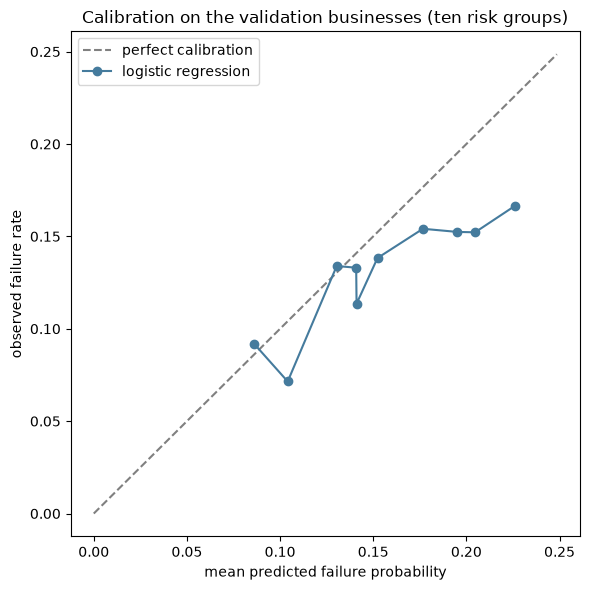

            businesses predicted observed
risk group                               
1                18318      8.6%     9.2%
2                18317     10.4%     7.1%
3                18318     13.0%    13.4%
4                18317     14.1%    13.3%
5                18318     14.1%    11.4%
6                18317     15.2%    13.8%
7                18317     17.7%    15.4%
8                18318     19.5%    15.2%
9                18317     20.5%    15.2%
10               18318     22.6%    16.6%

By economic_sector (validation businesses):
                 businesses predicted observed difference (points)
economic_sector                                                   
unclassified         100629     17.5%    14.3%                +3.2
F                     41644     10.5%    10.2%                +0.3
G                     10989     18.7%    14.0%                +4.7
I                      7072     18.5%    15.7%                +2.8
H                      4985     12.8%    13.1%   

In [5]:
validation = parts['validation'].assign(predicted=p_validation)
validation['risk group'] = pd.qcut(validation['predicted'].rank(method='first'), 10, labels=range(1, 11))
by_group = validation.groupby('risk group', observed=True).agg(businesses=(TARGET, 'size'), predicted=('predicted', 'mean'),
                                                               observed=(TARGET, 'mean'))
fig, ax = plt.subplots(figsize=(6, 6))
limit = max(by_group['predicted'].max(), by_group['observed'].max()) * 1.1
ax.plot([0, limit], [0, limit], color='grey', ls='--', label='perfect calibration')
ax.plot(by_group['predicted'], by_group['observed'], marker='o', color='#457b9d', label='logistic regression')
ax.set_xlabel('mean predicted failure probability'); ax.set_ylabel('observed failure rate')
ax.set_title('Calibration on the validation businesses (ten risk groups)'); ax.legend()
plt.tight_layout(); plt.show()
print(by_group.to_string(formatters={'predicted': '{:.1%}'.format, 'observed': '{:.1%}'.format}))

for column in INPUTS:
    by_value = validation.groupby(column).agg(businesses=(TARGET, 'size'), predicted=('predicted', 'mean'), observed=(TARGET, 'mean'))
    by_value['difference (points)'] = (by_value['predicted'] - by_value['observed']) * 100
    print(f'\nBy {column} (validation businesses):')
    print(by_value.sort_values('businesses', ascending=False).to_string(
        formatters={'predicted': '{:.1%}'.format, 'observed': '{:.1%}'.format, 'difference (points)': '{:+.1f}'.format}))

**Result.** The predicted probabilities rise from 8.6% in the lowest risk group to 22.6% in the highest, while the
observed failure rates rise from 9.2% to 16.6%. The predictions agree with the observations in the lowest groups and
overstate failure in the highest ones, by up to six points. The predicted failure exceeds the observed failure in
every region (by 0.6 to 6.4 points) and in every sector except transportation (H, −0.3 points).

**Interpretation.** The model orders the ideas in the right direction, but its probabilities are slightly
pessimistic for the validation businesses, mainly because they failed less often than the training businesses. The
probability shown to the founder is therefore a cautious estimate.

## 7. Stage 5 — Weights Learned by the Logistic Regression

Each weight is the change in the log-odds of failing that a category adds. It is shown as an odds ratio
(exp(weight)): above 1, the category raises the odds of failing; below 1, it lowers them. As every category has its
own column, the ratios compare each category with the average of its input rather than with a reference category.

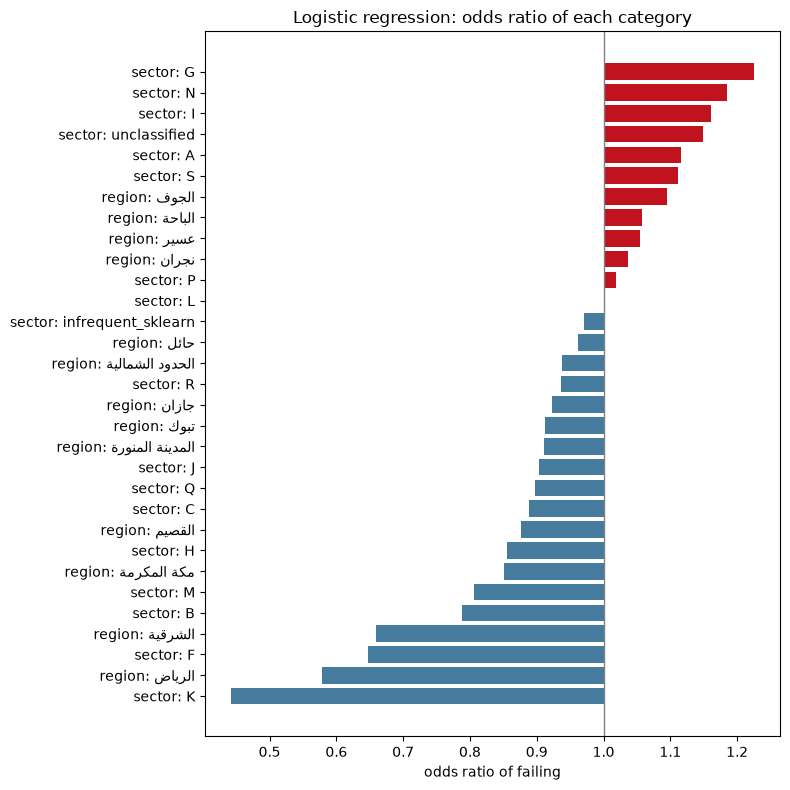

          input           category weight odds ratio training businesses
economic_sector                  K -0.816       0.44               2,694
         region             الرياض -0.547       0.58             112,643
economic_sector                  F -0.435       0.65              84,728
         region            الشرقية -0.417       0.66              47,441
economic_sector                  B -0.238       0.79                 605
economic_sector                  M -0.216       0.81               6,133
         region        مكة المكرمة -0.162       0.85              53,589
economic_sector                  H -0.157       0.85              13,248
         region             القصيم -0.133       0.88              14,264
economic_sector                  C -0.119       0.89              10,595
economic_sector                  Q -0.109       0.90               2,057
economic_sector                  J -0.102       0.90               4,853
         region    المدينة المنورة -0.093       0.9

In [6]:
names = logistic.named_steps['prepare'].get_feature_names_out()
weights = pd.Series(logistic.named_steps['model'].coef_[0], index=names)
input_of = [next(column for column in INPUTS if name.startswith(column + '_')) for name in names]
odds = pd.DataFrame({'input': input_of, 'category': [name[len(column) + 1:] for name, column in zip(names, input_of)],
                     'weight': weights.to_numpy(), 'odds ratio': np.exp(weights.to_numpy())})
counts = {column: parts['training'][column].value_counts() for column in INPUTS}
odds['training businesses'] = [counts[i].get(c, np.nan) for i, c in zip(odds['input'], odds['category'])]
odds = odds.sort_values('weight')
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(odds['input'].str.replace('economic_sector', 'sector') + ': ' + odds['category'], odds['odds ratio'] - 1, left=1,
        color=np.where(odds['odds ratio'] > 1, '#c1121f', '#457b9d'))
ax.axvline(1, color='grey', lw=1); ax.set_xlabel('odds ratio of failing')
ax.set_title('Logistic regression: odds ratio of each category')
plt.tight_layout(); plt.show()
print(odds.to_string(index=False, formatters={'weight': '{:+.3f}'.format, 'odds ratio': '{:.2f}'.format,
                                               'training businesses': '{:,.0f}'.format}))

**Result.** Financial and insurance activities (K, odds ratio 0.44), construction (F, 0.65), Riyadh (0.58) and the
Eastern Province (0.66) are associated with the lowest odds of failing. Wholesale and retail trade (G, 1.23),
administrative and support services (N, 1.18), accommodation and food services (I, 1.16) and Al-Jouf (1.09) are
associated with the highest.

**Interpretation.** Within the two inputs, the largest regions and the financial and construction activities are
associated with lower odds of failing, and retail trade and food services with higher odds. The weights describe
association in the records, not the effect of choosing a sector or region.

## 8. Stage 6 — Storage of the Model of Release 1

The logistic regression is saved as the model of Release 1 in the folder `models` of the data folder (never in
Git), together with a report of its inputs and validation scores, which the model service (`ml/src/model_service.py`)
reads. The report also records the share of each sector and region among the training businesses, which the model
service uses when the founder's idea is nationwide or its sector is not among the training categories. The scores of
both models are saved in `ml/reports/06_baseline_results.csv`.

In [7]:
training = parts['training']
report = {
    'model': 'release1_survival_model',
    'stage': 'Release 1 initial training (baseline logistic regression)',
    'trained_on': date.today().isoformat(),
    'algorithm': 'logistic regression without class weights',
    'inputs': INPUTS,
    'target': TARGET,
    'training_businesses': int(len(training)),
    'training_founding_quarters': sorted(training['founding_quarter'].unique().tolist()),
    'training_failure_rate': round(float(y['training'].mean()), 4),
    'validation_businesses': int(len(parts['validation'])),
    'validation_scores': {name: round(float(value), 4) for name, value in baseline.loc['logistic regression'].items()},
    'sector_shares': training['economic_sector'].value_counts(normalize=True).round(6).to_dict(),
    'region_shares': training['region'].value_counts(normalize=True).round(6).to_dict(),
}
MODELS.mkdir(parents=True, exist_ok=True)
joblib.dump(logistic, MODELS / 'release1_survival_model.joblib')
(MODELS / 'release1_survival_model_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))
baseline.to_csv(REPORTS / '06_baseline_results.csv', index_label='model', encoding='utf-8-sig')
print(f'Saved the model and its report to {MODELS}')
print(f'Saved the scores of both models to {REPORTS / "06_baseline_results.csv"}')
print(json.dumps({key: value for key, value in report.items() if not key.endswith('_shares')}, ensure_ascii=False, indent=2))

Saved the model and its report to /Users/halaalsabbar/darb-data/pipeline/models
Saved the scores of both models to /Users/halaalsabbar/Darb/2026-GP1-G17/ml/reports/06_baseline_results.csv
{
  "model": "release1_survival_model",
  "stage": "Release 1 initial training (baseline logistic regression)",
  "trained_on": "2026-11-22",
  "algorithm": "logistic regression without class weights",
  "inputs": [
    "economic_sector",
    "region"
  ],
  "target": "failed_first_year",
  "training_businesses": 292824,
  "training_founding_quarters": [
    "2023Q1",
    "2023Q2",
    "2024Q2",
    "2024Q4"
  ],
  "training_failure_rate": 0.1487,
  "validation_businesses": 183175,
  "validation_scores": {
    "PR-AUC": 0.1524,
    "ROC-AUC": 0.5638,
    "recall (failed)": 0.0,
    "precision (failed)": 0.0,
    "Brier": 0.1139,
    "failure rate": 0.1307,
    "mean predicted failure": 0.1557
  }
}


**Result.** The logistic regression was saved as `release1_survival_model.joblib`, with its report, and the scores
of both models were saved in `ml/reports/06_baseline_results.csv`.

**Interpretation.** This is the model of Release 1. It is replaced when a later model, with more inputs or a
stronger algorithm, gives better validation scores.

## 9. Limitations

1. The model uses two inputs, the sector and the region; the other business inputs and the market and economic
   conditions are not yet inputs.
2. The sector is inferred from the business name, and 28.3% of the training businesses are `unclassified`
   (Notebook 05, limitation 3); a founder always states a sector, so this category is never used for a prediction.
3. The training businesses were founded in four quarters only (Notebook 05, section 3.1), and none in a third
   quarter.
4. The scores are measured on the validation businesses, which are also used to compare the models; the final
   evaluation on the test businesses is made once, in Sprint 3.
5. The target reflects the continuity of a registration rather than the commercial performance of a business
   (Notebook 02, limitation 4).

## 10. Summary of Findings

1. The model of Release 1 is a logistic regression on the sector and the region, trained on 292,824 businesses with
   a complete survival check and evaluated on 183,175 validation businesses; the test businesses were not examined.
2. It ranks the validation businesses better than always the average (ROC-AUC 0.564 against 0.500; PR-AUC 0.152
   against 0.131), with an almost equal Brier score (0.1139 against 0.1140).
3. Its probabilities overstate failure by about two points on average (15.6% predicted against 13.1% observed), and
   by up to six points for the riskiest ideas.
4. Financial activities, construction, Riyadh and the Eastern Province are associated with the lowest odds of
   failing; retail trade, administrative services and food services with the highest.
5. The baseline that later models must beat is a ROC-AUC of 0.564 and a Brier score of 0.1139 on the validation
   businesses.